# Week 7: Hands-On ML Solution Data Visualizations

## Dataset 3: Social Media Interactions

### 1. Introduction

In this notebook, our team explores the cleaned social media interactions dataset from Milestone 1. We will examine interaction patterns, numerical distributions, and trends in the available data to identify useful insights for future machine learning tasks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Loading the Cleaned Dataset

Our team will use the preprocessed social media interactions dataset to continue the analysis without repeating the cleaning steps completed in Milestone 1.

In [2]:
social_media = pd.read_csv(
    "social_media_interactions_preprocessed.csv"
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### 3. Initial Dataset Inspection

We will review the dataset's dimensions, column names, data types, missing values, and duplicate records to understand the available information before creating visualizations.

In [3]:
display(social_media.head())

print("Dataset shape:", social_media.shape)

print("\nColumn names:")
print(social_media.columns.tolist())

print("\nData types:")
print(social_media.dtypes)

print("\nMissing values:")
print(social_media.isnull().sum())

print("\nDuplicate rows:", social_media.duplicated().sum())

,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
0,2dcb9523-356b-40b2-a67b-1f27797de261,e5d15761-d0a7-4329-89e3-79a892c56097,2023-07-11,Unknown,Comment,Unknown
1,e12c37b3-7d4d-472f-9fd8-0df2cb3001aa,02f9f376-70ae-4fcd-9070-1db977939948,2023-07-06,Twitter,Share,Unknown
2,08a911a3-65e6-4f5d-a6a1-ae7ddcbe28a2,a83fa04c-f109-4f24-8ce1-2078154f6a1c,2024-05-24,Instagram,Comment,Neutral
3,efdfdfc9-5dbb-4478-911a-101a390a0285,28a69c4b-a2e4-4c74-a130-1132d7733fdf,2023-11-01,Instagram,Like,Neutral
4,ca1e90f6-0e5f-492e-ab92-252ff540da18,d9d1c6f8-5e15-4738-b52b-13c2982420cc,2023-07-08,Instagram,Like,Unknown


Dataset shape: (3020, 6)

Column names:
['CustomerID', 'InteractionID', 'InteractionDate', 'Platform', 'InteractionType', 'Sentiment']

Data types:
CustomerID         str
InteractionID      str
InteractionDate    str
Platform           str
InteractionType    str
Sentiment          str
dtype: object

Missing values:
CustomerID         0
InteractionID      0
InteractionDate    0
Platform           0
InteractionType    0
Sentiment          0
dtype: int64

Duplicate rows: 0


### 4. Preparing the Interaction Dates

Our team will convert the interaction date column into a datetime format and extract the month and year for trend analysis. This will allow us to examine how social media activity changes over time.

In [4]:
social_media["InteractionDate"] = pd.to_datetime(
    social_media["InteractionDate"],
    errors="coerce"
)

print("Date range:")
print("Start:", social_media["InteractionDate"].min())
print("End:", social_media["InteractionDate"].max())

print(
    "\nInvalid dates:",
    social_media["InteractionDate"].isna().sum()
)

Date range:
Start: 2023-07-01 00:00:00
End: 2024-06-30 00:00:00

Invalid dates: 0


### 5. Descriptive Statistics of Social Media Interactions

Our team will summarize the categorical variables to identify the most common platforms, interaction types, and sentiment categories. We will also calculate the total number and percentage of records in each category.

In [5]:
categorical_columns = [
    "Platform",
    "InteractionType",
    "Sentiment"
]

for column in categorical_columns:
    print(f"\n{column} frequency:")
    print(social_media[column].value_counts(dropna=False))

    print(f"\n{column} percentage:")
    print(
        (
            social_media[column]
            .value_counts(normalize=True, dropna=False) * 100
        ).round(2)
    )


Platform frequency:
Platform
Instagram    921
Twitter      917
Facebook     891
Unknown      291
Name: count, dtype: int64

Platform percentage:
Platform
Instagram    30.50
Twitter      30.36
Facebook     29.50
Unknown       9.64
Name: proportion, dtype: float64

InteractionType frequency:
InteractionType
Comment    1018
Share      1007
Like        995
Name: count, dtype: int64

InteractionType percentage:
InteractionType
Comment    33.71
Share      33.34
Like       32.95
Name: proportion, dtype: float64

Sentiment frequency:
Sentiment
Positive         905
Neutral          874
Negative         866
Unknown          309
Very Negative     34
Very Positive     32
Name: count, dtype: int64

Sentiment percentage:
Sentiment
Positive         29.97
Neutral          28.94
Negative         28.68
Unknown          10.23
Very Negative     1.13
Very Positive     1.06
Name: proportion, dtype: float64


### 6. Visualization 1: Interactions by Platform

Our team will use a bar chart to compare the number of interactions recorded for each platform. This will help us identify the most represented platforms and determine how much of the dataset is labeled as Unknown.

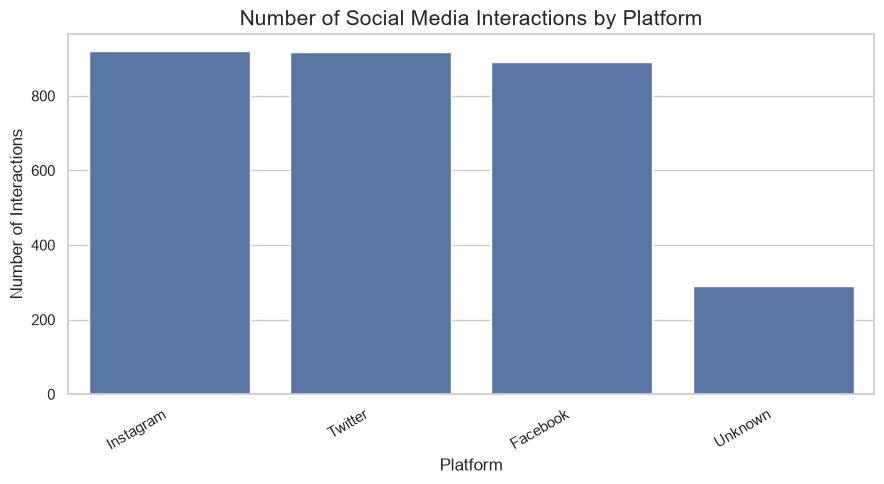

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=social_media,
    x="Platform",
    order=social_media["Platform"].value_counts().index
)

plt.title("Number of Social Media Interactions by Platform", fontsize=15)
plt.xlabel("Platform")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 7. Interpretation of Interactions by Platform

Our team observed that Instagram and Twitter have the highest numbers of recorded interactions, followed closely by Facebook. The Unknown category has considerably fewer records than the three identified platforms. This suggests that most interactions are associated with known platforms, although the Unknown entries may limit the accuracy of platform comparisons.

### 8. Visualization 2: Interaction Types

Our team will compare the frequency of likes, comments, and shares using a bar chart. This will help us identify the most common ways customers interact with social media content.

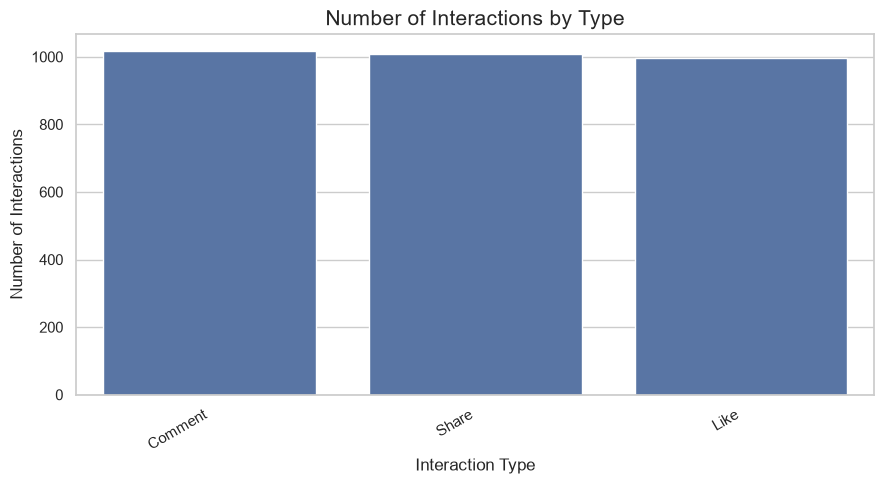

In [7]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=social_media,
    x="InteractionType",
    order=social_media["InteractionType"].value_counts().index
)

plt.title("Number of Interactions by Type", fontsize=15)
plt.xlabel("Interaction Type")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 9. Interpretation of Interaction Types

Our team observed that Comments have the highest number of interactions, followed closely by Shares, while Likes have a slightly lower count. The differences are small, suggesting that the three interaction types occur at relatively similar rates. These results can help our team understand how customers engage with social media content.

### 10. Visualization 3: Sentiment Distribution

Our team will compare the number of records labeled Positive, Neutral, Negative, and Unknown using a bar chart. This will help us understand the sentiment information available in the dataset and identify how many interactions still have an Unknown sentiment.

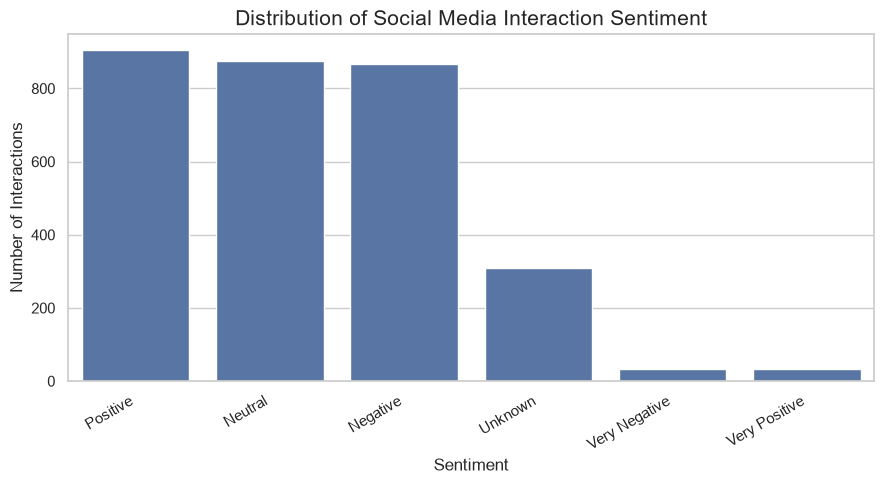

In [8]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=social_media,
    x="Sentiment",
    order=social_media["Sentiment"].value_counts().index
)

plt.title("Distribution of Social Media Interaction Sentiment", fontsize=15)
plt.xlabel("Sentiment")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 11. Interpretation of Sentiment Distribution

Our team observed that Positive sentiment has the highest count, followed by Neutral and Negative sentiment, with all three categories having relatively similar frequencies. The Unknown category is much smaller, while Very Positive and Very Negative appear only in a few records. These results show a mix of customer opinions, but the small counts in the extreme sentiment categories should be considered when interpreting the overall pattern.

### 12. Visualization 4: Monthly Interaction Trends

Our team will examine the number of interactions recorded each month to identify changes in social media activity over time. This can help us recognize periods of higher or lower engagement and determine whether the dataset shows any noticeable trends.

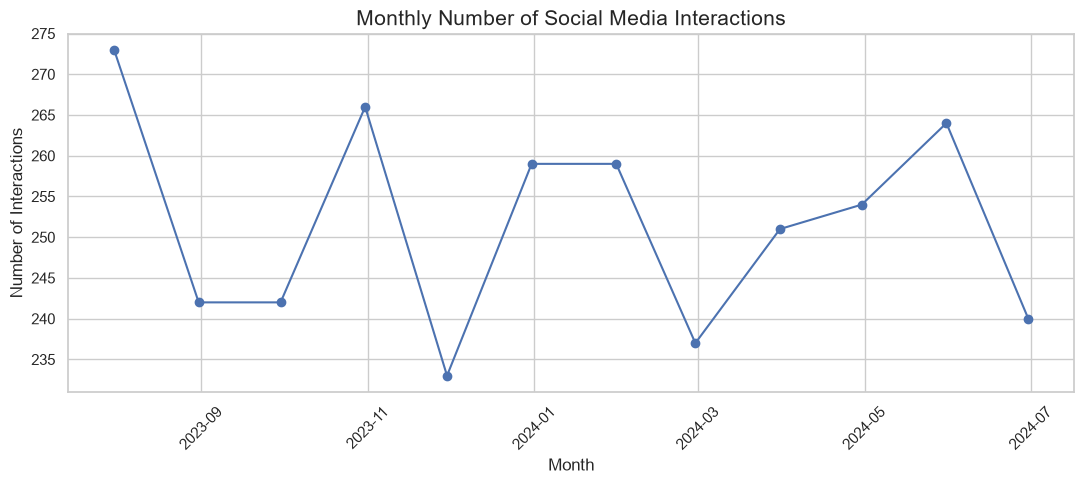

In [9]:
monthly_interactions = (
    social_media.dropna(subset=["InteractionDate"])
    .set_index("InteractionDate")
    .resample("ME")
    .size()
)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_interactions.index,
    monthly_interactions.values,
    marker="o"
)

plt.title("Monthly Number of Social Media Interactions", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 13. Interpretation of Monthly Interaction Trends

Our team observed that monthly social media interactions fluctuate between approximately 233 and 273 records during the period shown. Activity was highest around August 2023 and lowest around December 2023. The number of interactions later increased and decreased at different points, suggesting that engagement was not consistent each month. These patterns may help identify changes in activity, although more information would be needed to explain the reasons behind them.

## 14. Overall Findings and Machine Learning Relevance

Our analysis shows that Instagram and Twitter account for the largest numbers of recorded interactions, while Comments, Shares, and Likes occur at relatively similar rates. Positive sentiment is the most common category, followed by Neutral and Negative, and monthly interaction counts fluctuate over time. These findings can help guide future machine learning tasks involving platform usage, interaction patterns, and sentiment analysis. Our team should also consider the Unknown platform and sentiment records when preparing data for modeling.